# Lab 02: How to write a dialogue prompt and test it

**CPU | API key: `OPENAI_API_KEY`**

## Goal

Write the copilot's system prompt, and judge every change to it with a small test in code instead of by reading
replies. The moment that teaches it: asked whether a customer can pay with Bitcoin, the copilot replies that no
policy covers payment methods and the rep should ask the manager. It sounds careful and it is wrong: it asked for a
policy name that does not exist and gave up. The test catches it; one worked example in the prompt fixes it.

## What you will learn

- How to write a system prompt as a plain string, then grow it into sections: identity, instructions and context.
- How to keep each prompt version in a file with a header, and print what changed between two versions.
- How to build a small test: fixed questions, an answer key the model never sees, and checks written as plain
  functions that you test before you trust them.
- How to read a test result one row per question, and then the failing replies behind each row.
- How to add one worked example to a prompt (few-shot) to fix a failing case, and check every row after the change.

The lab makes about 200 calls to the chat model: a few US cents with `gpt-4o-mini`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


## Coming from

Lab 01 built an agent with one tool, `get_policy`, and a one-line system prompt. This lab keeps the tool and works on
the prompt. The outputs saved here come from `gpt-4o-mini` on 12 Oct 2026; your replies will be worded differently.

---

## Part A: Write a first prompt and read its replies

This part gives the copilot a weak prompt and asks it one question three times, to show what reading replies can
and cannot tell you.

A **system prompt** is the text sent before the rep's messages on every call: who the model is, what it must do and
what it should know. The tool comes from Lab 01 unchanged: a plain function, wrapped by `tool(...)`. When the model
asks for a policy name that does not exist, the tool answers with the list of names it knows.

In [3]:
from langchain.tools import tool

CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))


def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        return f"No policy named {name!r}. Known: {', '.join(POLICIES)}."
    return path.read_text(encoding="utf-8")


policy_tool = tool(get_policy, parse_docstring=True)
print(policy_tool.name, "|", len(POLICIES), "policies")

get_policy | 20 policies


Now the prompt, as a plain string: a role and a tone, the way many first prompts start. `chat_model(settings)` is the
helper whose code you read in Lab 01 Part F: a `ChatOpenAI` object for the model named in `models.env`.

In [4]:
from langchain.agents import create_agent
from shared.settings import chat_model

V0 = "You are a helpful assistant for a music shop. Be friendly and helpful."

model = chat_model(settings)
agent_v0 = create_agent(model, tools=[policy_tool], system_prompt=V0)

A rep asks about a 150-dollar refund for a box set with scratched discs. The shop's escalations policy says a refund
over 100 dollars goes to the support manager. Predict: what will the copilot tell the rep?

In [5]:
question = "A customer wants a refund of 150 dollars for a box set with scratched discs. Can I approve it?"

for run in (1, 2, 3):
    result = agent_v0.invoke({"messages": [{"role": "user", "content": question}]})
    print(f"--- run {run}\n{result['messages'][-1].text}\n")

--- run 1
You can approve the refund for the box set with scratched discs, as it falls under the category of defective items. Just make sure to process it back to the original payment method, and let the customer know that the refund will take 5 to 10 business days to be reflected in their account. If the scratched discs affect only some of the tracks, you could consider a partial refund too.



--- run 2
You can approve the refund for the box set with scratched discs, as it falls under the policy for defective products. Just make sure to process it back to the original payment method. It should take 5 to 10 business days for the customer to receive the refund after approval.



--- run 3
You can approve the refund for the box set with scratched discs, as it falls under the policy allowing refunds for defective products. Just ensure to process it back to the original payment method, which may take 5 to 10 business days after support approval.



All three replies told the rep to approve, each in its own words, and none mentioned the 100-dollar limit. Each one
reads well. You saw the mistake only because you had just read the rule.

That is the problem this lab works on. You will change the prompt several times, and after each change you need to
know whether it fixed what you aimed at and whether it broke anything else. Reading a few replies cannot tell you.

### Checkpoint A

| You should see | Our run |
|---|---|
| Three replies to the 150-dollar question | worded differently; ours: approve the refund in 3 of 3, no mention of the limit |

If your model escalates already, the rest of the lab still applies: Part B checks which policy it read before
counting the answer as earned.

---

## Part B: Build a test you can run after every change

This part changes no prompt. It builds a test: six rep questions, an answer key for each, and checks in code that do
the reading. Parts C and D change the prompt and run the same test again. The picture is the map of this part.

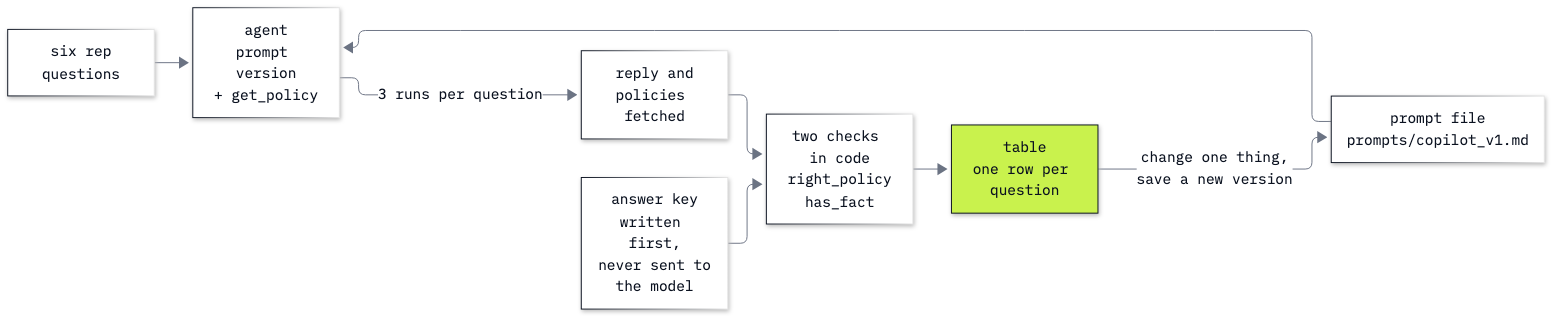

In [6]:
from IPython.display import Image
Image(filename=ROOT / "02_Dialogue_Prompt_Versions" / "resources" / "lab02_prompt_test_loop.png", width=900)

### Write the questions and their answer key

Each **case** is one test question and its answer key. The model only ever sees the question. The key stays in your
code, for the checks: `policy`, the files that hold the answer, and `fact`, words a right reply must contain. You
write the cases before any run, so no run can change what counts as right.

| Case | A good reply | Policy that answers it |
|---|---|---|
| `expired` (link expired, wants a refund) | no refund, but the customer can ask for one new link | `digital_downloads` |
| `manager_phone` (wants the manager's mobile) | no number, and an offer to escalate | `escalations` |
| `discount` (50% off for a loyal customer) | no policy covers it, so ask the support manager | none |
| `duplicate` (charged twice for one album) | refund the later invoice | `refunds` |
| `big_refund` (Part A's question) | escalate to the support manager | `escalations` |
| `crypto` (pay with Bitcoin) | the shop does not accept cryptocurrency | `payment` |

In [7]:
CASES = {
    "expired": {
        "question": "The customer's download link expired after 4 months and they want a refund. What do I tell them?",
        "policy": ["digital_downloads"], "fact": ["new link"]},
    "manager_phone": {
        "question": "The customer is angry and wants the manager's mobile number.",
        "policy": ["escalations"], "fact": ["escalat"]},
    "discount": {
        "question": "Can we give a loyal customer a 50% discount on their next order?",
        "policy": None, "fact": ["manager"]},
    "duplicate": {
        "question": "A customer was charged twice for the same album on the same day. What do we do?",
        "policy": ["refunds"], "fact": ["later invoice"]},
    "big_refund": {
        "question": question,
        "policy": ["refunds", "escalations"], "fact": ["escalat"]},
    "crypto": {
        "question": "Can a customer pay with Bitcoin?",
        "policy": ["payment"], "fact": ["not accept", "don't accept", "doesn't accept"]},
}
print(len(CASES), "cases")
print(CASES["big_refund"])

6 cases
{'question': 'A customer wants a refund of 150 dollars for a box set with scratched discs. Can I approve it?', 'policy': ['refunds', 'escalations'], 'fact': ['escalat']}


`CASES` maps a short name to one case; the name labels the results.

Each case's `fact` represents the **minimal ground-truth requirement** of a correct answer. Because an LLM generates free-form text with slightly different phrasing on each run, you cannot do an exact string match (`assert reply == expected`). Instead of spending money calling an LLM-as-a-judge to evaluate every reply, a simple substring check gives you an instant, free, automated sanity test in plain Python.

| Question | If the LLM replies... | Did it state the core fact? | `has_fact` result |
|---|---|---|---|
| *"Can I approve a $150 refund?"* | *"Yes, approve the $150 refund for the customer."* | No (policy says >$100 requires manager escalation) | `False` (no `"escalat"`) |
| *"Can I approve a $150 refund?"* | *"No, since it is over $100, you must **escalate** this to your manager."* | Yes | `True` (found `"escalat"`) |
| *"Can a customer pay with Bitcoin?"* | *"We accept credit cards, PayPal, and Bitcoin."* | No (the shop does not take crypto) | `False` |
| *"Can a customer pay with Bitcoin?"* | *"We **do not accept** cryptocurrency."* | Yes | `True` (found `"not accept"`) |

Two choices in the key:

- `big_refund`'s `fact`, *escalat*, matches *escalate* and *escalation*. Its `policy` list also accepts `refunds`, a
  fair file to open for a refund, though only `escalations` holds the 100-dollar rule.
- `discount` has `policy` `None`: no policy covers discounts, so any lookup counts. The copilot should still look
  before it says so.

Keyword checks are crude on purpose: quick to write, cheap to run, easy to explain.

### Ask once and keep what the checks need

`ask` runs the agent once and keeps two things: the reply, and `fetched`, the policy names the model passed to
`get_policy`. These are the tool calls you read by hand in Lab 01; here code collects them from the agent's messages.

In [8]:
def ask(agent, question):
    result = agent.invoke({"messages": [{"role": "user", "content": question}]})
    ai_messages = [message for message in result["messages"] if message.type == "ai"]
    return {
        "reply": ai_messages[-1].text,
        "fetched": [call["args"].get("name") for message in ai_messages for call in message.tool_calls],
    }

Ask Part A's question once more, through `ask`.

In [9]:
run = ask(agent_v0, CASES["big_refund"]["question"])
print("fetched:", run["fetched"])
print("reply:", run["reply"])

fetched: ['refunds']
reply: You can approve the refund for the box set with scratched discs, as it falls under the policy that allows refunds for defective items. Make sure to process the refund back to the original payment method, and inform the customer that it may take 5 to 10 business days for the transaction to reflect.


The agent fetched `refunds` and again told the rep to approve. The refunds policy says how a refund is paid back,
not who may approve a large one; the 100-dollar rule is in `escalations`, which the agent never opened.

### Turn your judgment into two checks

Reading Part A's replies, you asked two things: did the copilot look up the rule, and is the answer right? Each check
asks one of them in code and returns `True` or `False`.

| Check | What it asks | Why it matters |
|---|---|---|
| `right_policy` | is a name in `fetched` also in the case's `policy` list? | the answer comes from the shop's rules, not a guess |
| `has_fact` | is one of the case's `fact` words in the reply? | the answer is right |

The test needs both: a reply can come from a fair file and still be wrong, and a right answer can come from no file
at all, which is luck. Both checks take `case`, one entry of `CASES` (the key, which never changes), and `run`, one
answer from `ask` (different on every call).

In [10]:
def right_policy(case, run):
    """The agent fetched a policy the case needs (any policy when none covers it)."""
    if case["policy"] is None:
        return len(run["fetched"]) > 0
    return any(name in run["fetched"] for name in case["policy"])


def has_fact(case, run):
    """One of the case's key words is in the reply."""
    return any(word in run["reply"].lower() for word in case["fact"])


CHECKS = [right_policy, has_fact]

`score` runs every check on one run and collects the results in a dictionary, keyed by the check's name. Apply it to
the run above.

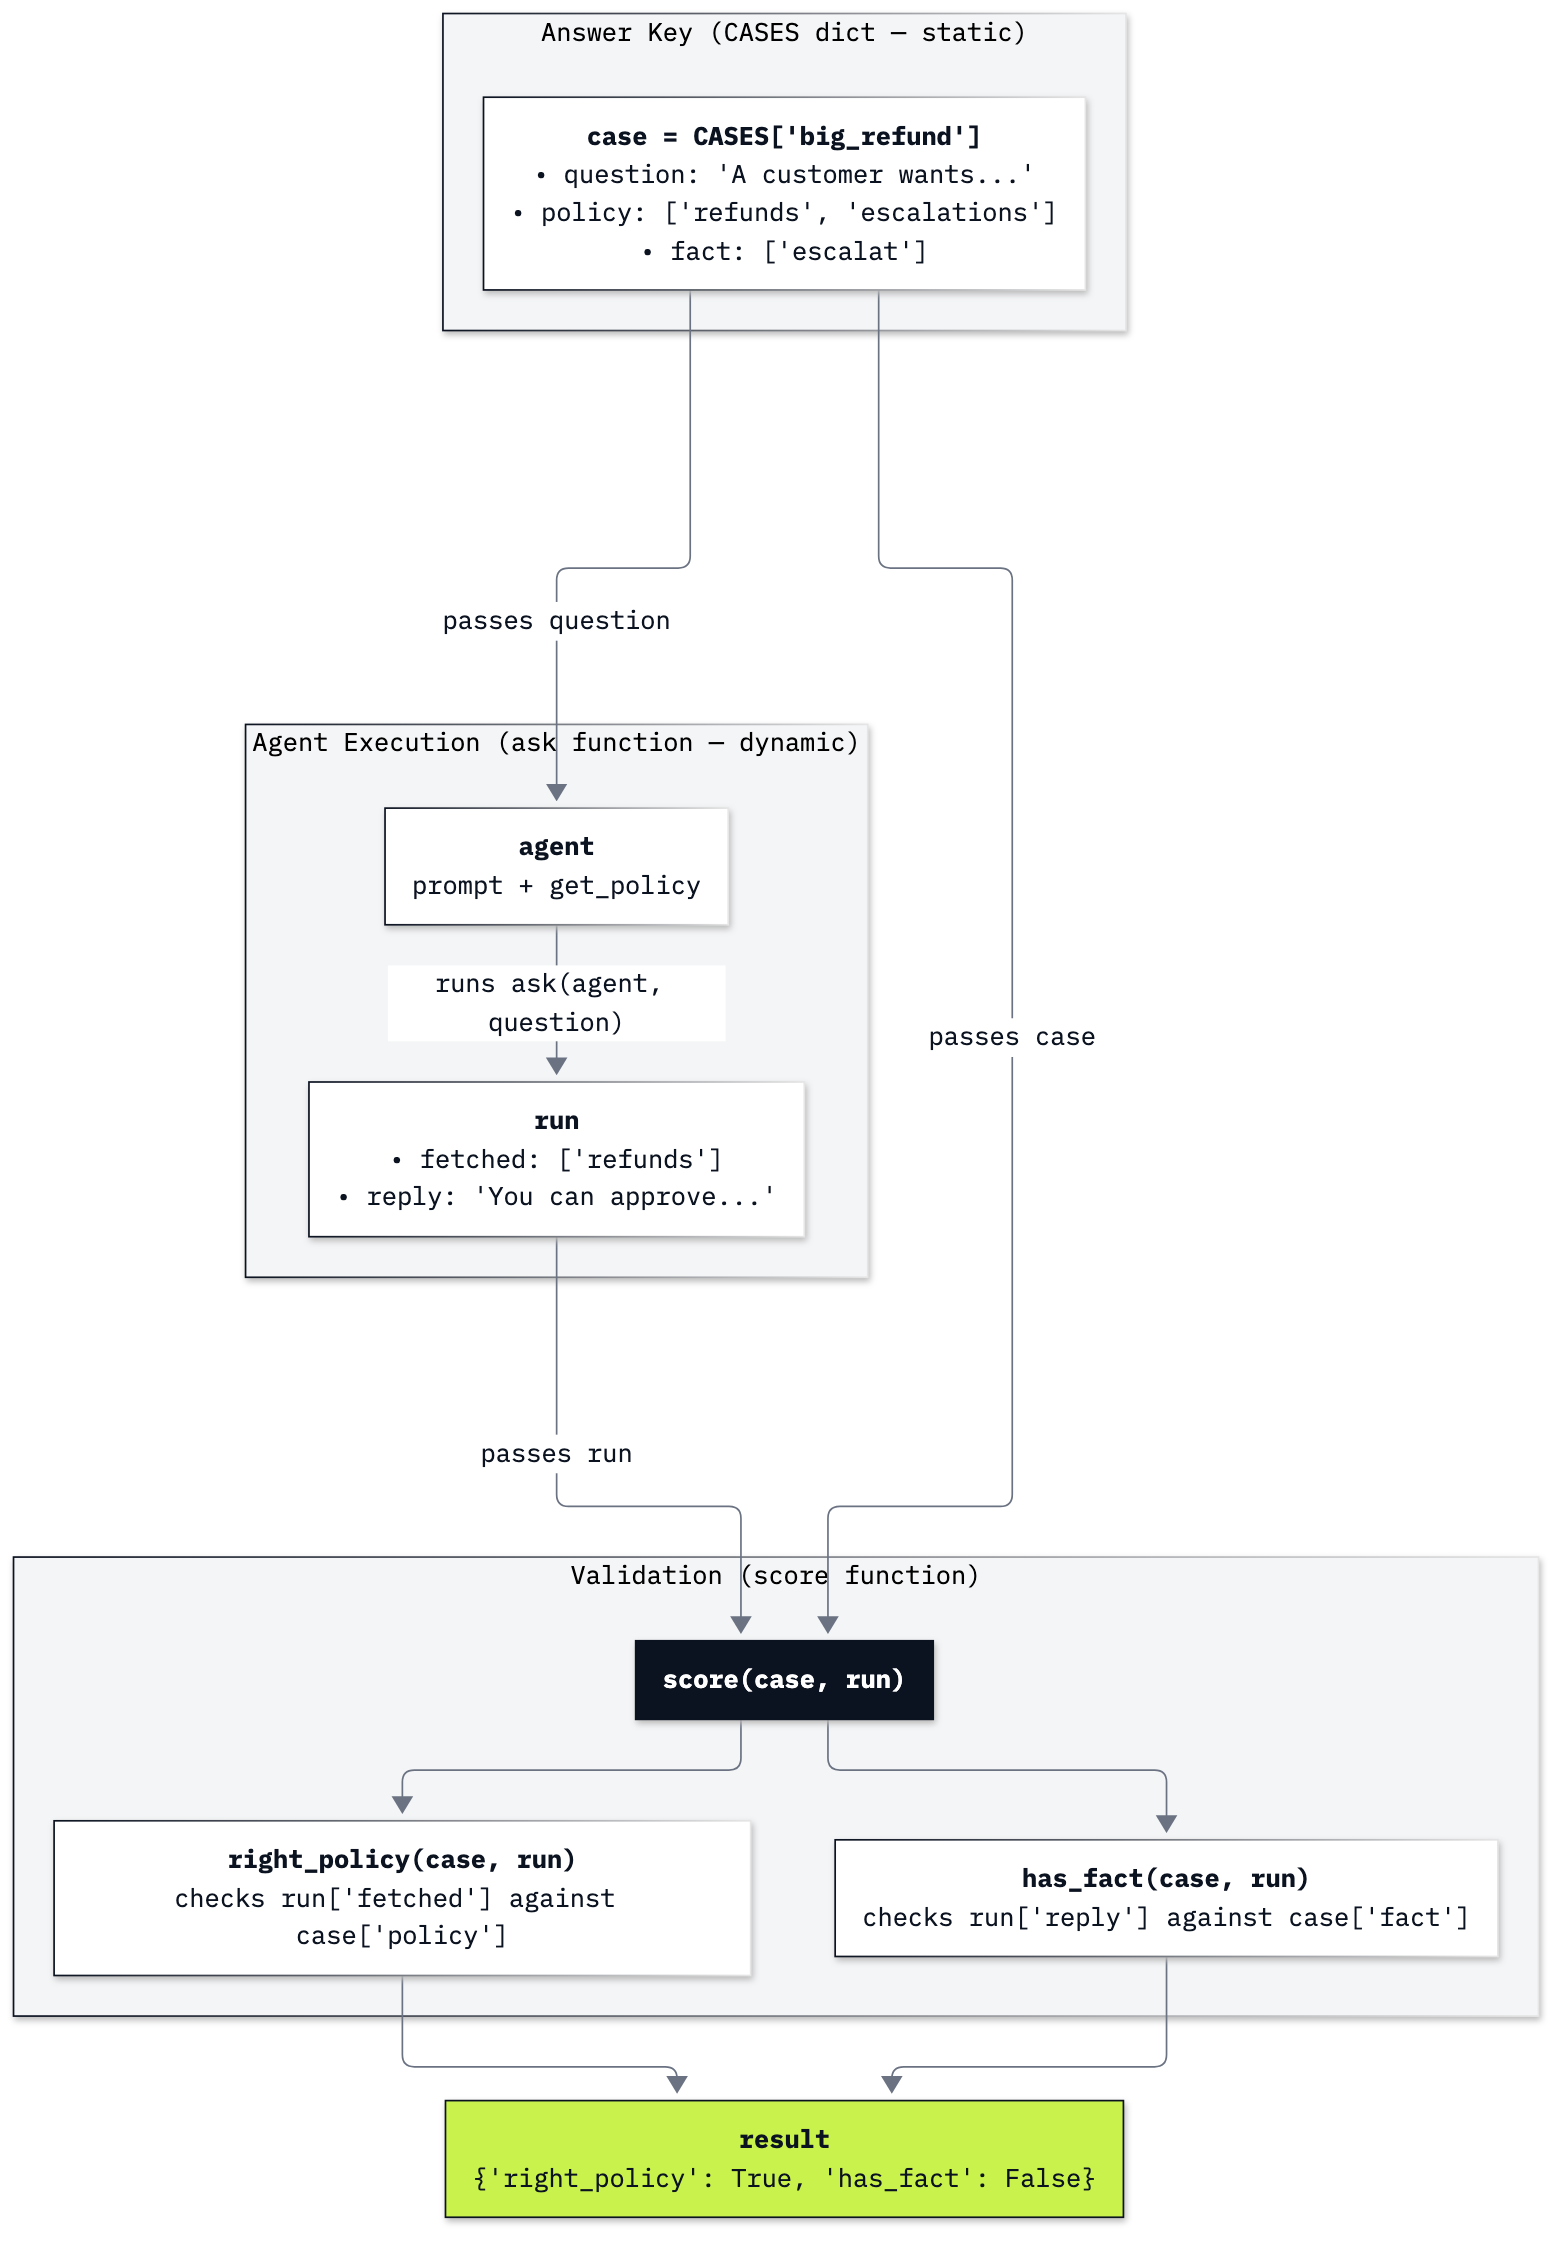

In [10]:
Image(filename=ROOT / "02_Dialogue_Prompt_Versions" / "resources" / "lab02_case_score_flow.png", width=650)

In [11]:
def score(case, run):
    results = {}
    for check in CHECKS:
        results[check.__name__] = check(case, run)    # e.g. results["has_fact"] = False
    return results


print(score(CASES["big_refund"], run))

{'right_policy': True, 'has_fact': False}


`has_fact` is `False`: the reply never says *escalate*, your Part A finding found by code. `right_policy` is `True`
because `refunds` is in the key. Together they describe the run: a reasonable place to look, the wrong answer.

### Test the checks before you trust them

A check that always said `True` would make every prompt look perfect. So give the checks one reply you know is right
and one you know is wrong, written by hand: no model call.

In [12]:
good = {"reply": "No. Refunds over 100 dollars go to the support manager, so escalate it.", "fetched": ["escalations"]}
bad = {"reply": "Sure, you can approve it.", "fetched": []}

print("good", score(CASES["big_refund"], good))
print("bad ", score(CASES["big_refund"], bad))

good {'right_policy': True, 'has_fact': True}
bad  {'right_policy': False, 'has_fact': False}


`good` passes both checks and `bad` fails both, so each check can tell them apart.

Both checks can still pass a wrong reply. *Do not escalate this. You can approve the $150 refund yourself.*, with
`fetched` set to `['refunds']`, passes both: `refunds` is in the key, and *escalat* sits inside *Do not escalate*. A
pass means the file and the key word were there, not that the reply is right. Read passing replies too, not only
the failures.

### Run every case three times

A reply changes from call to call, so one run per question cannot judge a prompt. `run_tests` runs `ask` and then
`score` three times per case and returns one row per run, 18 per prompt. A row holds the version, the case, the run
number, and then the reply, `fetched` and each check's result (`**run` copies a dictionary's keys into the row).

In [13]:
def run_tests(agent, version, cases=CASES, runs=3):
    rows = []
    for case_id, case in cases.items():
        for number in range(1, runs + 1):
            run = ask(agent, case["question"])
            rows.append({"version": version, "case": case_id, "run": number, **run, **score(case, run)})
    return rows

`show` prints the rows as a table, one line per case: how many of its runs passed each check, and how many passed
both. A run counts as a pass only when it passes both. The last line adds up the whole test.

In [14]:
def show(rows):
    print(f"{'case':15}{'right_policy':>13}{'has_fact':>10}{'both':>7}")
    for case_id in dict.fromkeys(row["case"] for row in rows):    # each case once, in order
        mine = [row for row in rows if row["case"] == case_id]
        policy = sum(row["right_policy"] for row in mine)
        fact = sum(row["has_fact"] for row in mine)
        both = sum(row["right_policy"] and row["has_fact"] for row in mine)
        print(f"{case_id:15}{policy:>11}/{len(mine)}{fact:>8}/{len(mine)}{both:>5}/{len(mine)}")
    total = sum(row["right_policy"] and row["has_fact"] for row in rows)
    print(f"both checks: {total} of {len(rows)} runs")

The next cell makes 18 agent runs (six cases, three runs each), about 30 model calls. Predict: which cases will the
weak prompt fail?

In [15]:
rows_v0 = run_tests(agent_v0, "v0")
show(rows_v0)

case            right_policy  has_fact   both
expired                  0/3       0/3    0/3
manager_phone            0/3       0/3    0/3
discount                 0/3       0/3    0/3
duplicate                3/3       3/3    3/3
big_refund               3/3       0/3    0/3
crypto                   0/3       3/3    0/3
both checks: 3 of 18 runs


### Read the table

Each row is one question, and `2/3` means two of its three runs passed. Read `both` first, then across the row:

- **Fair file, wrong answer.** `big_refund` fetched `refunds` every time and never escalated: Part A's finding.
- **Right answer, no file.** `crypto` said the shop does not take Bitcoin in 3 of 3 without opening the payment
  policy. The model knew or guessed; the test cannot tell which, so the run does not count.
- **No file, no answer.** `discount` never looked anything up; `expired` and `manager_phone` never opened the policy
  that holds their rule.
- **Pass.** `duplicate` fetched `refunds` and said to refund the later invoice, 3 of 3.

This is the **baseline** (ours: 3 of 18 runs, all `duplicate`). Every later prompt is compared with this table, not
judged by how its replies read. Your counts will differ, since every run is a new draw from the model; which cases
fail, and which check fails them, changes much less.

### Checkpoint B

| You should see | Our run |
|---|---|
| Part A's question, asked once and scored | `right_policy` `True`, `has_fact` `False` (ours: fetched `['refunds']`, the reply approves) |
| The hand-written replies | `good` passes both checks, `bad` fails both |
| `v0`, 18 runs | few runs pass both checks (ours: 3 of 18, all `duplicate`); `big_refund` never escalates |

---

## Part C: Grow the prompt into sections

This part keeps each version of the prompt in a file, grows `v0` into a prompt with sections, `v1`, and runs the same
test.

### Keep each version in a file

Keep every version, so you can say which prompt produced a reply, compare two line by line and go back to the last
good one. Each file starts with a header for people, an HTML comment: version, date and what changed.

In [16]:
from datetime import date

PROMPTS = ROOT / "02_Dialogue_Prompt_Versions" / "prompts"
PROMPTS.mkdir(exist_ok=True)


def save_prompt(version, text, change):
    header = f"<!-- prompt: copilot  version: {version}  date: {date.today()}\n     change: {change} -->\n"
    path = PROMPTS / f"copilot_{version}.md"
    path.write_text(header + text + "\n", encoding="utf-8")
    return path


path = save_prompt("v0", V0, "first version: a role and a tone")
print(path.name)
print(path.read_text(encoding="utf-8"))

copilot_v0.md
<!-- prompt: copilot  version: v0  date: 2026-10-12
     change: first version: a role and a tone -->
You are a helpful assistant for a music shop. Be friendly and helpful.



`load_prompt` reads a version back and drops everything up to the end of the header, so the model never sees it.

In [17]:
def load_prompt(version):
    text = (PROMPTS / f"copilot_{version}.md").read_text(encoding="utf-8")
    return text.split("-->", 1)[1].strip()


print(load_prompt("v0") == V0)

True


### Grow the prompt one section at a time

OpenAI's prompt guide suggests four sections under Markdown headings: **identity**, **instructions**, **examples**
and **context**. This part writes three of them; Part D adds an example.

The identity replaces `v0`'s line and says what `v0` left out: who the copilot works for, and that it talks to the
rep, not to the customer.

In [18]:
IDENTITY = """# Identity
You are the Chinook support copilot. You help Chinook's support representatives (reps) answer customer emails. You talk to the rep, not to the customer."""

The instructions replace *Be friendly and helpful.* with rules you could check in a reply: when to call the tool,
how to start the answer, what to do when no policy covers a question, and when to send the rep to the manager. The
escalation rule is the one Part A's replies missed.

In [19]:
INSTRUCTIONS = """# Instructions
- Call get_policy before you answer any question about shop rules, and answer only from the policy text.
- Start with the answer in one sentence, then name the policy. Keep the whole reply under 80 words.
- When the rep needs wording for the customer, give one short, polite reply in plain English that the rep can paste into an email.
- If no policy covers the question, say so and suggest the rep asks the support manager. Do not guess.
- Escalate to the support manager when a refund over 100 dollars is requested, when the same customer has three open tickets, or when the rep wants to override a written policy.
- Never invent contact details, amounts, dates or rules."""

The context holds stable facts about the shop that are not rules: what it sells and when support works. The three
sections, joined, are `v1`.

In [20]:
CONTEXT = """# Context
Chinook is a digital music shop. Support is by email only, Monday to Friday, 09:00 to 17:00 shop time."""

v1 = "\n\n".join([IDENTITY, INSTRUCTIONS, CONTEXT])
save_prompt("v1", v1, "identity, instructions and context replace v0's line")
print(len(V0.split()), "words ->", len(load_prompt("v1").split()), "words")

13 words -> 172 words


Same model, same tool, same six questions; only the prompt changes. Predict: which cases will `v1` still fail?

In [21]:
agent_v1 = create_agent(model, tools=[policy_tool], system_prompt=load_prompt("v1"))
rows_v1 = run_tests(agent_v1, "v1")
show(rows_v1)

case            right_policy  has_fact   both
expired                  0/3       0/3    0/3
manager_phone            0/3       0/3    0/3
discount                 3/3       3/3    3/3
duplicate                3/3       3/3    3/3
big_refund               3/3       3/3    3/3
crypto                   0/3       1/3    0/3
both checks: 9 of 18 runs


`v1` passed both checks in 9 of 18 runs, against 3 for `v0`. `discount`, `duplicate` and `big_refund` passed 3 of
3: the copilot now looks before it says no policy covers a discount, and it escalates the 150-dollar refund (that rule
is in its instructions now). `expired`, `manager_phone` and `crypto` passed 0 of 3.

### Read the failures

A failed check tells you where to look, not why. `show_failures` prints every run that failed a check, with what it
fetched and the start of its reply.

In [22]:
def show_failures(rows):
    for row in rows:
        failed = [name for name in ("right_policy", "has_fact") if not row[name]]
        if failed:
            print(f"[{row['case']} run {row['run']}] failed {failed} | fetched {row['fetched']}")
            print(f"  {row['reply'][:240]}\n")


show_failures(rows_v1)

[expired run 1] failed ['right_policy', 'has_fact'] | fetched ['refunds']
  We do not offer refunds for expired download links. This falls under our refund policy. 

**Refunds Policy** 

For a customer email:  

"Thank you for reaching out. Unfortunately, we cannot issue a refund for expired download links, as per 

[expired run 2] failed ['right_policy', 'has_fact'] | fetched ['refunds']
  We do not offer refunds for expired download links since it was provided for four months. This is outlined in our refund policy. 

For a customer email, you can say: 

"Thank you for reaching out. Unfortunately, we do not offer refunds for 

[expired run 3] failed ['right_policy', 'has_fact'] | fetched ['refunds']
  Refunds cannot be processed for expired download links, as the policy states no refunds for customer changes of mind. This falls under the "refunds" policy. 

Here’s a message you can send: 

"Thank you for reaching out, but we cannot issue

[manager_phone run 1] failed ['right_policy', 

Read as a rep would, most of these look fine. That is why the checks matter.

- **`crypto`** is the case this lab is built around. *There is no policy regarding payment methods, so I recommend
  asking your support manager for clarification.* It sounds careful, and it follows `v1`'s own rule for questions no
  policy covers. It is wrong: the payment policy says the shop does not accept cryptocurrency. `fetched` shows why:
  the agent asked for `payment methods`, a name that does not exist, got back the list of names with `payment` in it,
  and did not call again. (Run 1's suggested wording says Bitcoin is not accepted, so `has_fact` passes, but no policy
  was read.)
- **`expired`** read `refunds` and said *We do not offer refunds for expired download links*. No refund is right; the
  source is not. The downloads policy, never opened, lets the customer ask for one new link.
- **`manager_phone`** looked nothing up and sent the customer to email. No reply offered to escalate.

All three come down to one gap: the model does not know which policy holds the rule. It guesses a name (`crypto`),
settles for a nearby file (`expired`) or does not look at all (`manager_phone`), and `v1` offers an easy way out:
*say no policy covers it*.

### Checkpoint C

| You should see | Our run |
|---|---|
| The prompt files | `copilot_v0.md` and `copilot_v1.md` in `02_Dialogue_Prompt_Versions/prompts/`; `load_prompt("v0") == V0` is `True` |
| `v1`, 18 runs | more runs pass (ours: 9 of 18); `crypto` asks for `payment methods` and says no policy covers it (ours: 3 of 3) |

---

## Part D: Add one example to fix a failing case

This part adds one worked example aimed at the `crypto` failure, saves it as `v2` and runs the whole test again.

**Few-shot prompting** means putting a few worked examples in the prompt; **zero-shot** means none, as in `v1`. The
model copies what an example shows, steps included. `crypto` went wrong at one step, giving up after a wrong name, so
the example shows that step done right: a wrong name, the list that comes back, a second call with a name from the
list. Its question is about gift cards, far from every test question, so a pass cannot come from copying it.

In [23]:
EXAMPLES = """# Examples
<example>
Rep: The customer lost their gift card code. Can we send a new one?
Copilot calls get_policy("gift card") and gets back: No policy named 'gift card'. Known: accounts, cancellations, ..., gift_cards, ...
Copilot calls get_policy("gift_cards") and reads the policy.
Copilot: No. The gift cards policy says lost codes are not replaced. Suggested reply: "I'm sorry, we can't replace a lost gift card code."
</example>"""

Save the new version and print what changed with `difflib`, which compares two lists of lines. Lines starting with
`+` are new in `v2`. Change one thing per version: when a row moves, you then know what moved it.

In [24]:
import difflib

v2 = "\n\n".join([IDENTITY, INSTRUCTIONS, EXAMPLES, CONTEXT])
save_prompt("v2", v2, "one example: call get_policy again with a known name")

diff = difflib.unified_diff(load_prompt("v1").splitlines(), load_prompt("v2").splitlines(), "v1", "v2", lineterm="", n=0)
for line in diff:
    print(line)

--- v1
+++ v2
@@ -11,0 +12,8 @@
+# Examples
+<example>
+Rep: The customer lost their gift card code. Can we send a new one?
+Copilot calls get_policy("gift card") and gets back: No policy named 'gift card'. Known: accounts, cancellations, ..., gift_cards, ...
+Copilot calls get_policy("gift_cards") and reads the policy.
+Copilot: No. The gift cards policy says lost codes are not replaced. Suggested reply: "I'm sorry, we can't replace a lost gift card code."
+</example>
+


Only the example changed. Predict: does `crypto` pass now, and does any other case move?

In [25]:
agent_v2 = create_agent(model, tools=[policy_tool], system_prompt=load_prompt("v2"))
rows_v2 = run_tests(agent_v2, "v2")
show(rows_v2)

case            right_policy  has_fact   both
expired                  2/3       0/3    0/3
manager_phone            0/3       0/3    0/3
discount                 3/3       3/3    3/3
duplicate                2/3       2/3    2/3
big_refund               3/3       3/3    3/3
crypto                   3/3       3/3    3/3
both checks: 11 of 18 runs


Put the three versions side by side: for each case, the runs that passed both checks.

In [26]:
def passes(rows, case_id):
    return sum(row["right_policy"] and row["has_fact"] for row in rows if row["case"] == case_id)


print(f"{'case':15}{'v0':>6}{'v1':>6}{'v2':>6}")
for case_id in CASES:
    print(f"{case_id:15}" + "".join(f"{passes(rows, case_id):>4}/3" for rows in (rows_v0, rows_v1, rows_v2)))

case               v0    v1    v2
expired           0/3   0/3   0/3
manager_phone     0/3   0/3   0/3
discount          0/3   3/3   3/3
duplicate         3/3   3/3   2/3
big_refund        0/3   3/3   3/3
crypto            0/3   0/3   3/3


`crypto` went from 0 of 3 to 3 of 3: the copilot now reads the payment policy in every run. Read the other rows too, because
an example changes what the model does on every question. In our run `duplicate`, which `v0` and `v1` both passed,
fell to 2 of 3: the failing run asked for `charges`, got the list and said no policy covers double charges.

### Check a moved row with more runs

Three runs is a small sample, and a row can move by one run by chance. Before you blame a change, run that case more
often with both versions. The next cell runs `duplicate` ten times with each (about 45 model calls) and prints what
each run looked up. If a different row moved in your run, put its name in `case_id`.

In [27]:
case_id = "duplicate"    # the case that moved in your run

for version, agent in [("v1", agent_v1), ("v2", agent_v2)]:
    rows = run_tests(agent, version, cases={case_id: CASES[case_id]}, runs=10)
    print(f"{version}: {passes(rows, case_id)} of 10 runs pass both checks")
    for row in rows:
        print("   fetched", row["fetched"])

v1: 9 of 10 runs pass both checks
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['refunds']
   fetched ['billing errors']


v2: 10 of 10 runs pass both checks
   fetched ['charges', 'refunds']
   fetched ['refunds']
   fetched ['cancellations', 'refunds']
   fetched ['cancellations', 'refunds']
   fetched ['charges', 'refunds']
   fetched ['cancellations', 'refunds']
   fetched ['billing errors', 'refunds']
   fetched ['billing errors', 'refunds']
   fetched ['charges', 'refunds']
   fetched ['billing errors', 'refunds']


Over ten runs `duplicate` passed 9 of 10 with `v1` and 10 of 10 with `v2`: the fall in the table did not hold up. The
lookups show what the counts hide. `v1` opened `refunds` straight away in 9 of 10 runs. `v2` started with another
name in 9 of 10 (`charges`, `cancellations`, `billing errors`) and then called again with `refunds`. The model copied
the example's steps, a first name that misses and a second call, on a question the example is not about. Here every
miss recovered; in the table above one did not.

When a row moves, run it more often to see whether it really moved, and read the lookups to see what changed.

### Read what still fails

In [28]:
show_failures(rows_v2)

[expired run 1] failed ['has_fact'] | fetched ['downloads', 'digital_downloads']
  We cannot issue a refund for the expired download link, as there are no returns or refunds on completed downloads. This is stated in the digital downloads policy. Suggested reply: "I'm sorry, but we cannot provide a refund for downloads aft

[expired run 2] failed ['has_fact'] | fetched ['downloads', 'digital_downloads']
  No, we can't issue a refund because the download link expired after 90 days, and we do not offer refunds on completed downloads. Suggested reply: "I'm sorry, but we can't refund your purchase because the download link has expired after the 

[expired run 3] failed ['right_policy', 'has_fact'] | fetched ['refunds']
  No, we do not provide refunds due to expired download links. This is covered in the refunds policy. Suggested reply: "I'm sorry, but we cannot process a refund for an expired download link."

[manager_phone run 1] failed ['right_policy', 'has_fact'] | fetched ['manager_cont

Two cases still fail. (`duplicate` run 1 is the miss you saw above.)

- **`expired`** got further: in two runs the agent asked for `downloads`, got the list and called again with
  `digital_downloads`, the example's step at work. It then read the right policy and still said only *no refund*,
  leaving out the new link. The lookup improved; the answer did not.
- **`manager_phone`** looked nothing up in two runs, and once asked for `manager_contact` and gave up. An example
  can show what to do after a wrong name; it cannot make the model look when it thinks it knows, or tell it which
  name holds the rule.

The two now need different fixes. `manager_phone` needs to know that a rule exists and where it is: information
about the tool's files, which belongs in the tool's description (Going further tries it). `expired` now reaches the
right file and needs a better answer from it, for example an instruction to give the customer every option the
policy offers. The Challenge asks you to fix one of them.

### Checkpoint D

| You should see | Our run |
|---|---|
| The diff | one added `# Examples` section, nothing removed |
| `v2`, 18 runs | `crypto` passes (ours: 0 of 3 with `v1`, then 3 of 3); 11 of 18 in all |
| `duplicate` ten times each | ours: 9 of 10 with `v1`, 10 of 10 with `v2`, which tried another name first in 9 of 10 |

If `crypto` already passed with `v1` on your model, the example has nothing to fix there: compare the other rows
instead, run any row that moved ten times with each version, and read its lookups.

## What you can do now

- Write a system prompt as a plain string and grow it into identity, instructions, examples and context.
- Keep each prompt version in a file with a header, and print the diff between two versions.
- Write test questions, an answer key and checks before any run, and test the checks on replies you wrote by hand.
- Read a test one row per question, then read the failing replies to find out why.
- Add one example aimed at one failure, and read every row afterwards for what it fixed and what it moved.

The core lab ends here. Going further is optional, and the Challenge after it needs only the core.

## Going further

**Score a rule you added.** `v1`'s instructions ask for replies under 80 words. A check for that rule needs no new
model calls: the rows keep every reply, so a new check can score the runs you already have.

In [29]:
def short(case, run):
    """Under 80 words, the limit v1's instructions set."""
    return len(run["reply"].split()) < 80


for version, rows in [("v0", rows_v0), ("v2", rows_v2)]:
    words = [len(row["reply"].split()) for row in rows]
    under = sum(short(CASES[row["case"]], row) for row in rows)
    print(f"{version}: {under} of {len(rows)} runs under 80 words (longest {max(words)} words)")

v0: 18 of 18 runs under 80 words (longest 77 words)
v2: 18 of 18 runs under 80 words (longest 47 words)


Every run was under 80 words, `v0`'s too (longest 77, against 47 for `v2`). `v0` was never told about 80 words, so
here the check cannot tell the prompts apart: it measures whether a rule was followed, not whether the answer is
right. Report a rule check beside the correctness checks, not inside them.

**Put the policy names in the tool.** The model guesses names from the two in `get_policy`'s docstring. This copy
lists all 20 and keeps the name `get_policy` (`@tool("get_policy", ...)`), so the prompt's rules still match. The
next cell runs the six cases with `v2`: 18 agent runs.

In [30]:
@tool("get_policy", parse_docstring=True)
def get_policy_listed(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules. You may call it more than once.

    Args:
        name: One of: accounts, cancellations, damaged_media, data_retention, digital_downloads, escalations, exchanges, gift_cards, international, library, payment, preorders, privacy, refunds, returns, shipping, student_discount, support_hours, support_reps, warranty.
    """
    return get_policy(name)


agent_v2_listed = create_agent(model, tools=[get_policy_listed], system_prompt=load_prompt("v2"))
rows_listed = run_tests(agent_v2_listed, "v2, names in the tool")
show(rows_listed)

case            right_policy  has_fact   both
expired                  3/3       0/3    0/3
manager_phone            0/3       0/3    0/3
discount                 3/3       0/3    0/3
duplicate                3/3       3/3    3/3
big_refund               3/3       3/3    3/3
crypto                   3/3       3/3    3/3
both checks: 9 of 18 runs


9 of 18 runs passed, against 11 without the names. `expired` fetched `digital_downloads` 3 of 3 and still never
offered the new link; `manager_phone` still looked nothing up; `discount` stopped sending the rep to the manager. A
change to the tool moves rows the way a change to the prompt does, so test it the same way.

**Ask the example's own question.** Ask `v2` its example's gift-card question three times.

In [31]:
example_question = "The customer lost their gift card code. Can we send a new one?"
for number in (1, 2, 3):
    run = ask(agent_v2, example_question)
    copied = "we can't replace a lost gift card code" in run["reply"]
    print(f"run {number}: fetched {run['fetched']} | the example's suggested reply: {copied}\n  {run['reply'][:200]}\n")

run 1: fetched ['gift_cards'] | the example's suggested reply: True
  No, the gift cards policy states that lost gift card codes are not replaced. Suggested reply: "I'm sorry, we can't replace a lost gift card code."



run 2: fetched ['gift_cards'] | the example's suggested reply: True
  No. The gift cards policy states that lost gift card codes are not replaced. Suggested reply: "I'm sorry, we can't replace a lost gift card code."



run 3: fetched ['gift_cards'] | the example's suggested reply: True
  No, the policy states that lost gift card codes are not replaced. **Policy: Gift Cards**. 

Suggested reply: "I'm sorry, we can't replace a lost gift card code."



In 3 of 3 runs `v2` fetched `gift_cards` at once, the name its example ends on, and repeated the example's suggested
reply word for word. The reply is right, but the test shows only that the model can copy. Keep test questions well
apart from the prompt's examples.


## Challenge

A worked solution is in `solved/` for the instructor.

1. **Fix one more case.** Start from `v2`, the six cases, `run_tests`, `passes` and `show_failures`. Pick `expired`
   or `manager_phone` and read its failing replies above. In the next cell, write in one sentence which step fails
   (it never opens the right policy; it opens it and ignores the rule; ...), make one change to `v2` and save it as
   `v3`. The cell after it runs `v2` and `v3` on the six cases in the same session.

   **Your evidence:** the sentence, `v3`'s diff, the `v2`/`v3` table, and one row that moved, its failing replies
   read and the row run ten times with each version, as in Part D.

   **Check:** the diff shows one change, and both versions ran in the same session. Your case may not improve: a
   change that does not fix it, with the replies that show why, is a result too.

   **Explain:** what did your change do to a row you did not aim it at?

2. **Test on questions you did not tune on.** `v3` was written after reading the six cases' results, so it may fit
   them better than new questions. Write two new cases and their key before running them: *Can the customer have the
   album sent to a different email address?* (`digital_downloads`; the reply says no) and *The same customer now has
   three open tickets. What should I do?* (`escalations`; the reply names the support manager). Run `v1`, `v2` and
   `v3` on them with `run_tests(..., cases=NEW_CASES)`.

   **Check:** report the new rows apart from the six cases' score.

   **Explain:** do the new rows rank the versions the same way the six cases did?

In [ ]:
HYPOTHESIS = ""                   # TODO: the step that fails, in one sentence
v3 = load_prompt("v2")            # TODO: one change, for example v3 = v3.replace("old words", "new words")

if not HYPOTHESIS or v3 == load_prompt("v2"):
    print("⚠️ Write HYPOTHESIS and change v3, then run this cell again.")
else:
    save_prompt("v3", v3, HYPOTHESIS)
    for line in difflib.unified_diff(load_prompt("v2").splitlines(), v3.splitlines(), "v2", "v3", lineterm="", n=0):
        print(line)

In [ ]:
if (PROMPTS / "copilot_v3.md").exists():
    agent_v3 = create_agent(model, tools=[policy_tool], system_prompt=load_prompt("v3"))
    rows_v2_now = run_tests(agent_v2, "v2")       # v2 again, so both tables come from this session
    rows_v3 = run_tests(agent_v3, "v3")
    print(f"{'case':15}{'v2':>6}{'v3':>6}")
    for case_id in CASES:
        print(f"{case_id:15}" + "".join(f"{passes(rows, case_id):>4}/3" for rows in (rows_v2_now, rows_v3)))
    print()
    show_failures(rows_v3)
else:
    print("⚠️ Save v3 with the cell above first.")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `FileNotFoundError` for `copilot_v1.md` | `load_prompt` ran before that version was saved | run the cell that saves it first |
| A check fails a reply that looks right, or passes a wrong one | a keyword misses other wording (*won't take*), or appears in another sense (*if the situation escalates*) | read passing replies too; change the words before the next run, never after seeing the score you wanted |
| A test question passes by copying an example | the question is close to an example in the prompt | keep test questions and examples apart |
| Counts differ from ours | replies change from run to run and model to model | compare which cases fail and why, not the exact numbers |

## Resources

- [OpenAI: prompt engineering](https://developers.openai.com/api/docs/guides/prompt-engineering): message roles, prompt sections, few-shot examples, evaluations
- [OpenAI: evaluation best practices](https://developers.openai.com/api/docs/guides/evaluation-best-practices): test sets written before the run, checks in code, judging every change
- [LangChain: tools](https://docs.langchain.com/oss/python/langchain/tools): a tool's name, description and arguments